---
title: "Titanic EDA with Numpy, a first pass"
short_title: "Titanic EDA"
description: "The Titanic dataset analysed with Numpy alone: missing values, survival rates by sex, a first classifier, and a look at correlations."
---

In this notebook we use nothing but Numpy (no Pandas, no scikit-learn or the like) to carry out a discrete analysis of the Kaggle Titanic dataset. The obvious tasks are exploratory data analysis (EDA) and modelling the variable 'probability of survival' for the instances (an extract from the Titanic's passenger list). Along the way, and by way of motivation, we also take a first look at a multivariate analysis, even though we have not yet covered the theory behind it.

## Loading the data

To begin with, we naively load the comma-separated file from Kaggle (the one that comes with a header row) and see what happens.

In [1]:
import numpy as np

filename = 'titanic.csv'

try:
    data = np.genfromtxt(
        filename,
        delimiter=',',
        dtype=None,
        encoding='utf-8',
        names=True
    )
except ValueError as e:
    print("\n".join(e.args[0].split("\n")[:3]), "\n\t...")

Some errors were detected !
    Line #2 (got 13 columns instead of 12)
    Line #3 (got 13 columns instead of 12) 
	...


Evidently line 2 contains more variables than the header row!

Let us print the first two lines and inspect them by hand:

In [2]:
with open(filename, "r") as file:
    for i in range(2):
        print(file.readline())

PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked

1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S



The fix is a CSV parser that understands quotation marks: in `"Braund, Mr. Owen Harris"` the comma is part of the name, not a separator. The `csv` module in the Python standard library can do that (and so can `pandas.read_csv`, which we will meet later). `np.genfromtxt` knows nothing about quotation marks, so we write the file out once as a TSV (tab-separated values). None of the values contains a tab, so the TSV no longer needs quotation marks:

In [3]:
import csv

with open("titanic.csv", newline="", encoding="utf-8") as source, \
     open("titanic.tsv", "w", encoding="utf-8") as target:
    for row in csv.reader(source):          # reads "Braund, Mr. Owen Harris" as one field
        assert not any("\t" in field for field in row)   # otherwise we would need quotation marks again
        target.write("\t".join(row) + "\n")

In [4]:
filename = 'titanic.tsv'

data = np.genfromtxt(
    filename,
    delimiter='\t',
    dtype=None,
    encoding='utf-8',
    names=True
)

In [5]:
print("Columns:", data.dtype.names)
print("First 5 rows:")
print(data[:5])

Columns: ('PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked')
First 5 rows:
[(1, 0, 3, 'Braund, Mr. Owen Harris', 'male', 22., 1, 0, 'A/5 21171',  7.25  , '', 'S')
 (2, 1, 1, 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)', 'female', 38., 1, 0, 'PC 17599', 71.2833, 'C85', 'C')
 (3, 1, 3, 'Heikkinen, Miss. Laina', 'female', 26., 0, 0, 'STON/O2. 3101282',  7.925 , '', 'S')
 (4, 1, 1, 'Futrelle, Mrs. Jacques Heath (Lily May Peel)', 'female', 35., 1, 0, '113803', 53.1   , 'C123', 'S')
 (5, 0, 3, 'Allen, Mr. William Henry', 'male', 35., 0, 0, '373450',  8.05  , '', 'S')]


## Selecting the relevant features

In [6]:
survived = data['Survived'].astype(int)
pclass = data['Pclass'].astype(int)
sex = data['Sex']
age = data['Age']  # may contain nan
sibsp = data['SibSp'].astype(int)
parch = data['Parch'].astype(int)
embarked = data['Embarked']

used_columns = {'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Embarked'}
all_columns = set(data.dtype.names)
unused_columns = all_columns - used_columns
print("Unused columns:", unused_columns)

Unused columns: {'Fare', 'Cabin', 'PassengerId', 'Ticket', 'Name'}


## NaN = Not a Number

Replacing missing values with the median or dropping those rows: either is a decision that distorts the data. How to take such decisions systematically and put them on record is covered in the chapter [Data cleaning](data-cleaning.ipynb).


In [7]:
print("\nNumber of missing age values:", np.sum(np.isnan(age)))

# replace missing age values by the median (just as an example)
non_nan_age = age[~np.isnan(age)]
age_filled = age.copy()
age_filled[np.isnan(age)] = np.median(non_nan_age)

print("Missing age values replaced by the median:", np.median(non_nan_age))


Number of missing age values: 177
Missing age values replaced by the median: 28.0


## Analysing survival

In [8]:
# new feature
def survival_rate(mask):
    total = np.sum(mask)
    survived_total = np.sum(survived[mask])
    rate = survived_total / total if total > 0 else 0
    return total, survived_total, rate

# group by Sex
for s in np.unique(sex):
    mask = (sex == s)
    total, survived_s, rate = survival_rate(mask)
    print(f"Sex: {s:6s} | Total: {total:3d} | Survived: {survived_s:3d} | Rate: {rate:.2f}")

# group by passenger class
for c in np.unique(pclass):
    mask = (pclass == c)
    total, survived_c, rate = survival_rate(mask)
    print(f"Pclass: {c} | Total: {total:3d} | Survived: {survived_c:3d} | Rate: {rate:.2f}")

# Binning
missing = np.isnan(age)  # keep track of the missing entries separately, no sentinel value!

age_group = np.full(age.shape, 'Unknown', dtype='<U10')
age_group[~missing] = 'Adult'
age_group[~missing & (age < 13)] = 'Child'
age_group[~missing & (age >= 60)] = 'Senior'

for grp in np.unique(age_group):
    mask = (age_group == grp)
    total, survived_grp, rate = survival_rate(mask)
    print(f"Age Group: {grp:7s} | Total: {total:3d} | Survived: {survived_grp:3d} | Rate: {rate:.2f}")

Sex: female | Total: 314 | Survived: 233 | Rate: 0.74
Sex: male   | Total: 577 | Survived: 109 | Rate: 0.19
Pclass: 1 | Total: 216 | Survived: 136 | Rate: 0.63
Pclass: 2 | Total: 184 | Survived:  87 | Rate: 0.47
Pclass: 3 | Total: 491 | Survived: 119 | Rate: 0.24
Age Group: Adult   | Total: 619 | Survived: 243 | Rate: 0.39
Age Group: Child   | Total:  69 | Survived:  40 | Rate: 0.58
Age Group: Senior  | Total:  26 | Survived:   7 | Rate: 0.27
Age Group: Unknown | Total: 177 | Survived:  52 | Rate: 0.29


## Visualisation: survival by sex

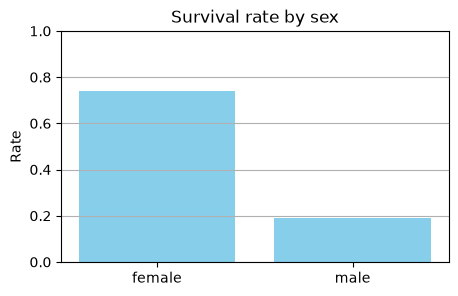

In [9]:
import matplotlib.pyplot as plt

labels = []
rates = []
for s in np.unique(sex):
    mask = (sex == s)
    _, _, rate = survival_rate(mask)
    labels.append(s)
    rates.append(rate)

plt.figure(figsize=(5, 3))
plt.bar(labels, rates, color='skyblue')
plt.title('Survival rate by sex')
plt.ylabel('Rate')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

## A first classifier

The survival rates above suggest a rule: "women survive, men do not". A rule that turns the features of a row into a **label** (here the column `Survived`) is called a **classifier**. The label is the column we want to predict; for the rows we already have it is known, and that is the *ground truth*. Before we learn any procedure that finds such a rule from data on its own, let us see how a rule is assessed. All that takes is masks:

In [10]:
prediction = (sex == 'female')    # prediction: survived
truth = (survived == 1)           # ground truth

tp = np.sum( prediction &  truth)   # true positive:  predicted survived, did survive
fp = np.sum( prediction & ~truth)   # false positive: predicted survived, died
fn = np.sum(~prediction &  truth)   # false negative: predicted died, did survive
tn = np.sum(~prediction & ~truth)   # true negative:  predicted died, did die

print("                   predicted: died  survived")
print(f"actually died:                {tn:4d}      {fp:4d}")
print(f"actually survived:            {fn:4d}      {tp:4d}")
assert tp + fp + fn + tn == len(survived)

                   predicted: died  survived
actually died:                 468        81
actually survived:             109       233


This $2 \times 2$ table is called the **confusion matrix**. It is nothing more than a cross-tabulation of two nominal variables, ground truth against prediction – exactly the kind of summary measure the chapter [Descriptive statistics](descriptive-statistics.md) allows for nominal features. Three summary measures in common use can be read off it:

* **Accuracy**: the proportion of correct predictions, $\dfrac{tp + tn}{n}$.
* **Precision**: when we predict "survived", how often is that right? $\dfrac{tp}{tp + fp}$.
* **Recall** (in medicine *sensitivity*): of those who actually survived, how many do we catch? $\dfrac{tp}{tp + fn}$.

Precision and recall are conditional probabilities, just read in opposite directions: precision is $P(\text{survived} \mid \text{predicted})$, recall is $P(\text{predicted} \mid \text{survived})$. That they are two different numbers is something we will meet again under [Bayes' theorem](covariance.md).

In [11]:
n = len(survived)

def summary_measures(prediction):
    tp = np.sum( prediction &  truth); fp = np.sum( prediction & ~truth)
    fn = np.sum(~prediction &  truth); tn = np.sum(~prediction & ~truth)
    accuracy  = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp > 0 else np.nan   # undefined without a positive prediction
    recall    = tp / (tp + fn)
    return accuracy, precision, recall

for name, pred in [("women survive", sex == 'female'),
                   ("nobody survives", np.zeros(n, dtype=bool))]:
    acc, prec, rec = summary_measures(pred)
    print(f"{name:18s} Accuracy {acc:.3f}   Precision {prec:.3f}   Recall {rec:.3f}")

women survive      Accuracy 0.787   Precision 0.742   Recall 0.681
nobody survives    Accuracy 0.616   Precision nan   Recall 0.000


The second row is the stupidest classifier there is: it predicts the most frequent class for every row. Even so, it is right 62% of the time, because only 38% of the passengers survived. This shows that accuracy on its own says little; it always has to be held up against the **base rate** of the most frequent class. Recall and precision expose the rule at once: recall $0$, precision undefined.

The stupidest classifier is, incidentally, an old acquaintance. In the chapter [Expected value and variance](expectation-variance.md), the median and the mean were the best *constant* models for the absolute and the squared error. For a nominal label the best constant model is the **mode**, the most frequent class, and the error it minimises is the misclassification rate $1 - \text{Accuracy}$.

The rule can be refined – following the maxim "women and children first", for instance:

In [12]:
acc, prec, rec = summary_measures((sex == 'female') | (~missing & (age < 13)))
print(f"Women and children Accuracy {acc:.3f}   Precision {prec:.3f}   Recall {rec:.3f}")

Women and children Accuracy 0.792   Precision 0.724   Recall 0.743


Accuracy barely changes, but recall rises and precision falls: the new rule catches more of the survivors, but it also mistakes more of the dead for survivors. Which of the two measures matters depends on the question. If you are planning lifeboats you want to overlook no survivor (recall); if you are sorting out spam you want to throw away no genuine email (precision). Because a single number is often what is needed, the two are combined into the **F1 score**, the harmonic mean of precision and recall. In the chapter [Model selection](model-selection.ipynb) we let scikit-learn compute this table for us.

We have allowed ourselves one thing here that must never be repeated later on: we assessed the rule on the very data we dreamt it up on. How to hold data back so that a rule can be assessed honestly is also in the chapter Model selection, under *train-test split*.

### Two directions

The confusion matrix holds one more lesson, which we only look at here and will not prove until the chapter [Covariance and dependence](covariance.md). The precision of the rule "women survive" is the proportion of survivors among the women; the recall is the proportion of women among the survivors:

In [13]:
p_survived_if_female = np.mean(survived[sex == 'female'])         # P(survived | female) = precision
p_female_if_survived = np.mean(sex[survived == 1] == 'female')    # P(female | survived) = recall
p_female = np.mean(sex == 'female')    # base rate: proportion of women
p_survived = np.mean(survived)         # base rate: survival rate

print(f"P(survived | female) = {p_survived_if_female:.3f}")
print(f"P(female | survived) = {p_female_if_survived:.3f}")
print(f"Conversion: {p_female_if_survived:.3f} * {p_survived:.3f} / {p_female:.3f}"
      f" = {p_female_if_survived * p_survived / p_female:.3f}")

P(survived | female) = 0.742
P(female | survived) = 0.681
Conversion: 0.681 * 0.384 / 0.352 = 0.742


The two conditional probabilities differ, and the conversion factor between them is the ratio of the two base rates. That, with numbers we counted ourselves, is **Bayes' theorem**.

## A look at correlations

We have not yet formally introduced what a correlation is, but let us quickly compute the so-called correlation coefficient all the same. How to interpret what we see here can wait until later.

In [14]:
is_female = (sex == 'female').astype(int)
is_male = (sex == 'male').astype(int)

corf = np.corrcoef(survived, is_female)[0, 1]
corm = np.corrcoef(survived, is_male)[0, 1]

print(f"Correlation between being female and survival: {corf:.2f}")
print(f"Correlation between being male and survival: {corm:.2f}")

Correlation between being female and survival: 0.54
Correlation between being male and survival: -0.54
